In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
#Librerias para realizar el arbol de desicion
from sklearn.tree import DecisionTreeRegressor,DecisionTreeClassifier, plot_tree
#DecisionTreeRegressor: Crea un arbol para predecir valores numericos en este caso ventas/Sales
#DecisionTreeClassifier: por el tipo de dataset no es muy logico pero por temas practicos aqui esta
#plot_tree : Simplemente nos permite dibujar el arbol
from sklearn.model_selection import train_test_split
#train_test_split: Separa los datos en entrenamiento y prueba
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
#mean_absolute_error	Calcula el promedio de los errores absolutos.
#mean_squared_error	Calcula el promedio de los errores al cuadrado.
#r2_score: Para evalúar qué tan bien el modelo explica la variación de las ventas/Sales

In [4]:
df = pd.read_csv('/content/drive/MyDrive/ArchivosAnalitica/Midataset/Dummy Data HSS.csv')
df

,TV,Radio,Social Media,Influencer,Sales
0,16.0,6.566231,2.907983,Mega,54.732757
1,13.0,9.237765,2.409567,Mega,46.677897
2,41.0,15.886446,2.913410,Mega,150.177829
3,83.0,30.020028,6.922304,Mega,298.246340
4,15.0,8.437408,1.405998,Micro,56.594181
...,...,...,...,...,...
4567,26.0,4.472360,0.717090,Micro,94.685866
4568,71.0,20.610685,6.545573,Nano,249.101915
4569,44.0,19.800072,5.096192,Micro,163.631457
4570,71.0,17.534640,1.940873,Macro,253.610411


In [5]:
df.shape

(4572, 5)

In [6]:
df.columns

Index(['TV', 'Radio', 'Social Media', 'Influencer', 'Sales'], dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4572 entries, 0 to 4571
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   TV            4562 non-null   float64
 1   Radio         4568 non-null   float64
 2   Social Media  4566 non-null   float64
 3   Influencer    4572 non-null   object 
 4   Sales         4566 non-null   float64
dtypes: float64(4), object(1)
memory usage: 178.7+ KB


In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
TV,4562.0,54.066857,26.125054,10.000000,32.000000,53.000000,77.000000,100.000000
Radio,4568.0,18.160356,9.676958,0.000684,10.525957,17.859513,25.649730,48.871161
Social Media,4566.0,3.323956,2.212670,0.000031,1.527849,3.055565,4.807558,13.981662
Sales,4566.0,192.466602,93.133092,31.199409,112.322882,189.231172,272.507922,364.079751


In [9]:
df.describe(include='object').T

,count,unique,top,freq
Influencer,4572,4,Mega,1158


In [10]:
df['Influencer'].value_counts()

,count
Influencer,
Mega,1158
Micro,1153
Nano,1139
Macro,1122


In [11]:
df.select_dtypes(include='object').nunique()

,0
Influencer,4


In [12]:
df.isnull().sum()

,0
TV,10
Radio,4
Social Media,6
Influencer,0
Sales,6


In [13]:
df.isnull().mean() * 100

,0
TV,0.218723
Radio,0.087489
Social Media,0.131234
Influencer,0.000000
Sales,0.131234


In [14]:
# como hay muy pocos valores faltantes simplemente se eliminaran

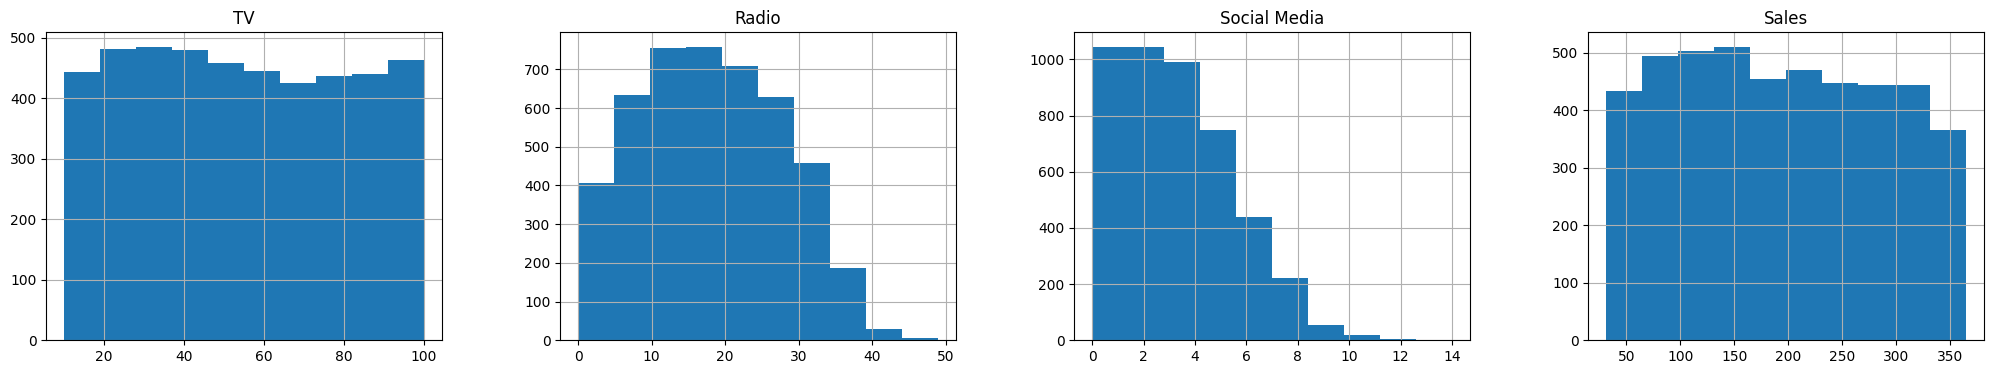

In [15]:
df.hist(figsize=(25,4), layout=(1,4))
plt.show()

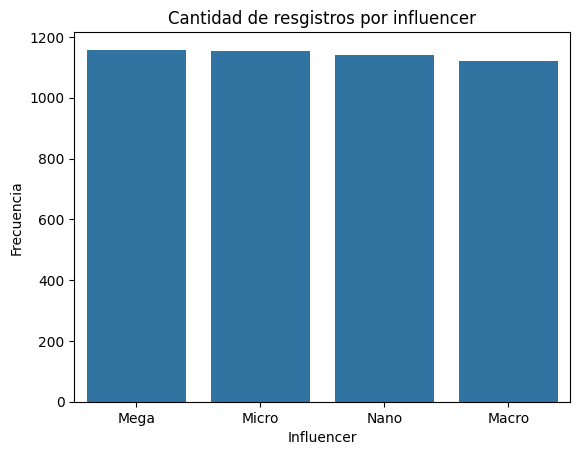

In [16]:
sns.countplot(x=df['Influencer'])
plt.title('Cantidad de resgistros por influencer')
plt.xlabel('Influencer')
plt.ylabel('Frecuencia')
plt.show()

<Axes: xlabel='Social Media', ylabel='Sales'>

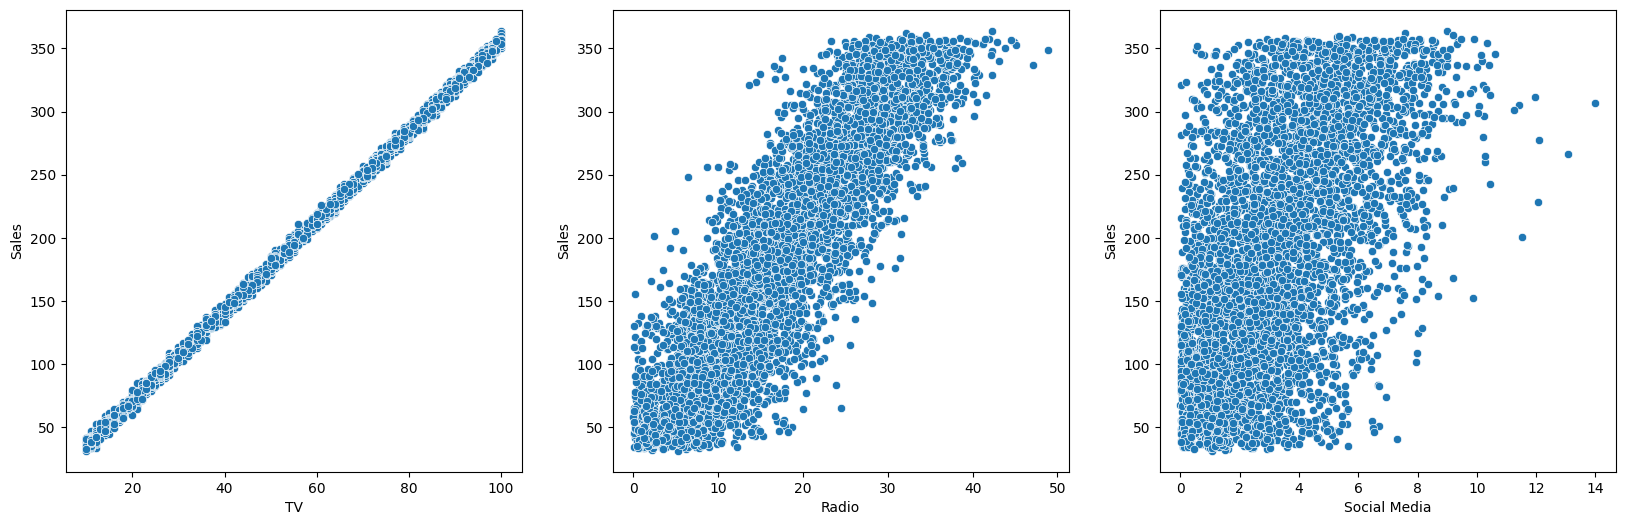

In [17]:
fig, axes = plt.subplots(1, 3, figsize = (20, 6))
sns.scatterplot(x='TV', y='Sales', data=df, ax=axes[0])
sns.scatterplot(x='Radio', y='Sales', data=df, ax=axes[1])
sns.scatterplot(x='Social Media', y='Sales', data=df, ax=axes[2])

<Axes: >

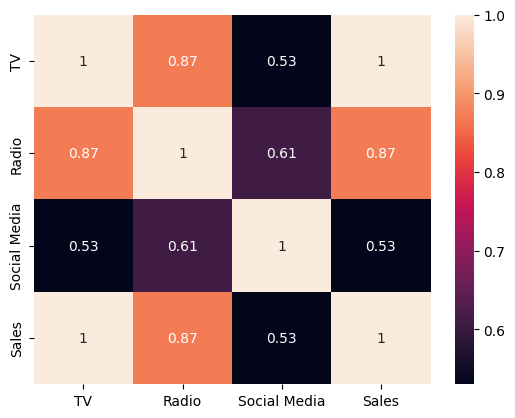

In [18]:
sns.heatmap(round(df.corr(numeric_only=True),2),annot=True)

Separacion de las variables, independientes y la dependiente

In [19]:
datos = df.dropna()# Esto es para eliminar las filas que tengan valores faltantes
#Se crea datos para no afectar el dataframe original
x = datos.drop( 'Sales', axis=1)
#X:contiene las caracteristicas que el arbol usara para predecir las ventas
y = datos['Sales']
#Y: contiene la variable a predecir(Sales)

In [20]:
#Preparacion de los datos
#Este tipo de arbol requiere un tratamiento especifico sobre los valores faltantes,
#En este csaso se usaran unicamente las filas completas
#Por otra parte la columna 'Influencer contiene palabras como 'Mega' entre otras.
#Es necesario covertir estas categorias en columnas numerucas.
x = pd.get_dummies(x, columns=['Influencer'], dtype=int)
#con este codigo se convierter las categorias en columnas con valores como 0 y 1
x.head()

,TV,Radio,Social Media,Influencer_Macro,Influencer_Mega,Influencer_Micro,Influencer_Nano
0,16.0,6.566231,2.907983,0,1,0,0
1,13.0,9.237765,2.409567,0,1,0,0
2,41.0,15.886446,2.913410,0,1,0,0
3,83.0,30.020028,6.922304,0,1,0,0
4,15.0,8.437408,1.405998,0,0,1,0


In [21]:
datos.isnull().sum()

,0
TV,0
Radio,0
Social Media,0
Influencer,0
Sales,0


Dividir los daos en entrenamiento y prueba

In [22]:
xtrain, xtest, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2, # facil, se reserva 20% de los datos para la evaluacion y el 80% para entrenar
    random_state=42) # para una semilla aleatoria


Crear y entrenar el abrbol de desición

*   Elemento de lista
*   Elemento de lista



In [23]:
model = DecisionTreeRegressor(
    max_depth=3,#Limita la profundidad del arbol a tres divisiones desde la raiz hasta una hoja
    # Es util porque si tenemos un arbol demasiado profundo puede memorizar datos del entrenamiento
    # en lugar de aprender patrones
    random_state=42
)

Entrenar el arbol con fit

In [24]:
model.fit(xtrain, y_train)

DecisionTreeRegressor(max_depth=3, random_state=42)

Visualizar el arbol

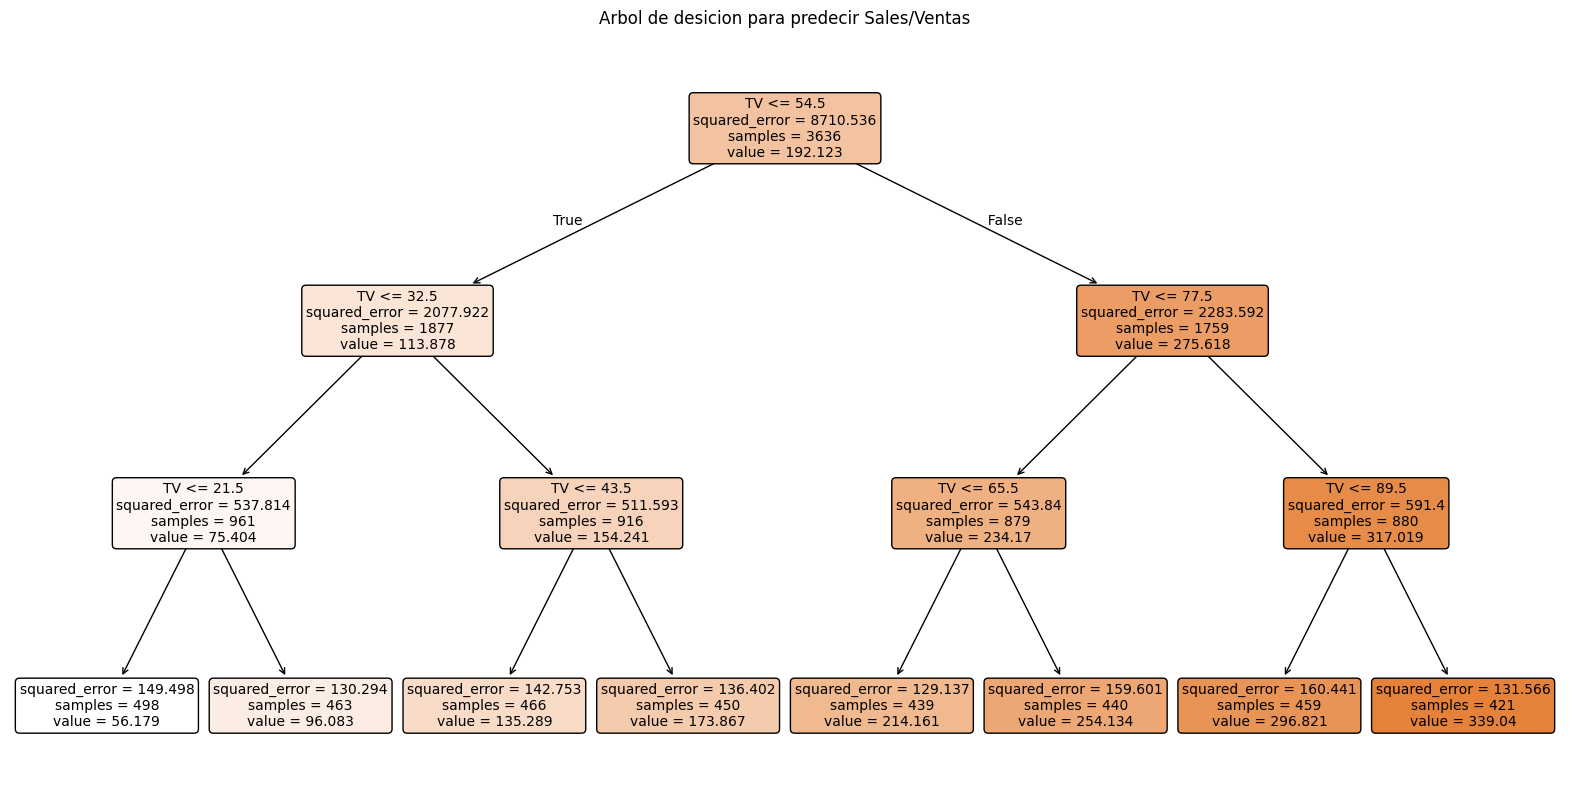

In [25]:
plt.figure(figsize=(20,10))

plot_tree(
    model,
    feature_names=x.columns,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title('Arbol de desicion para predecir Sales/Ventas')
plt.show()

<font color = "orange">
<div align="justify">
El árbol de decisión muestra que la inversión en publicidad por televisión (TV) es la variable que el modelo utiliza para predecir las ventas (Sales). A partir de los 3,636 registros de entrenamiento, el árbol establece diferentes condiciones para dividir los datos según el presupuesto destinado a televisión, identificando que, conforme aumenta la inversión, también aumentan las ventas estimadas. Por ejemplo, cuando la inversión es menor o igual a 21.5 millones, las ventas predichas son aproximadamente 56.18 millones, mientras que, para inversiones superiores a 89.5 millones, las ventas estimadas alcanzan los 339.04 millones. Además, aunque se incluyeron las variables Radio, Social Media e Influencer, el modelo seleccionó únicamente TV para realizar las divisiones, lo que indica que esta variable fue la más útil para reducir el error dentro del árbol construido. En general, los resultados muestran una relación positiva entre la inversión en televisión y las ventas, aunque es necesario evaluar el modelo con los datos de prueba para determinar qué tan precisas son sus predicciones.
</div>
</font>

Predicciones de Sales/Ventas

In [26]:
y_pred = model.predict(xtest)

In [27]:
#comprobando las ventas reales con las predichas
resultados = pd.DataFrame({
    'Ventas reales': y_test,
    'Ventas predichas': y_pred})
resultados.head(10)

,Ventas reales,Ventas predichas
497,55.261284,56.178669
3800,67.574904,56.178669
24,272.250108,254.134057
1918,195.102176,214.161379
142,273.960377,254.134057
1815,39.992087,56.178669
3357,147.150178,135.288545
2398,229.141912,214.161379
2345,222.696768,214.161379
3282,322.466797,339.039586


Calcular las metricas

In [28]:
mae = mean_absolute_error(y_test, y_pred) # Error absoluto promedio entre las ventas reales y las predichas
#en mae se busca un cercano a cero
mse = mean_squared_error(y_test, y_pred) # Promedio de errores elevado al cuadrado, se busca el cero o cercano
r2 = r2_score(y_test, y_pred)#Proporcion de variabilidad de ventas explicadas por el modelo
#se busca que sea cercano a 1
print(f'MAE: {mae}')#es para imprimir(pues si)
print(f'MSE: {mse}')
print(f'R2: {r2}')

MAE: 10.598745676128681
MSE: 150.63489106029252
R2: 0.9820894637146096


Interpretacion de metricas segun el dataset

<font color = "orange">
<div align="justify">
MAE = 10.60
Como el error absoluto medio mide cuanto se equivoca el modelo en promedio, sin importar si la prediccion esta por encima o debajo del valor real.Este valor quiere decir que las predicciones se alejan del valor real de las ventas por aproximadamente 10.60 millones en promedio.
MSE = 150.63
El error cuadratico medio calcula los errores en las predicciones y despues obtiene el promedio.
lo que provoca que los errores más grandes tengan un mayor impacto en el resultado.En este caso, se obtuvo un MSE de 150.63 millones al cuadrado. Esto no significa que el modelo se equivoque por 150.63 millones, sino que representa el promedio de los errores elevados al cuadrado.
R² = 0.9821
El coeficiente de determinación indica qué proporción de la variabilidad de las ventas consigue explicar el modelo, en comparación con utilizar una predicción constante basada en el promedio.
R² de 0.9821 indica que el árbol explica aproximadamente el 98.21 % de la variabilidad de las ventas en el conjunto de prueba.
</div>
</font>

Identificar las variables mas importantes para el modelo

In [29]:
importancia = pd.Series(
    model.feature_importances_,
    index=x.columns
)
importancia.sort_values(ascending=False)

,0
TV,1.0
Radio,0.0
Social Media,0.0
Influencer_Macro,0.0
Influencer_Mega,0.0
Influencer_Micro,0.0
Influencer_Nano,0.0


DecisionTreeClassifier

In [30]:
datos_cat = df.copy()

In [31]:
datos_cat = datos_cat.dropna()

In [32]:
x_cat = datos_cat.drop('Influencer', axis=1)# en realidad no tiene mucho sentido
#pero como no hay mas variables categoricas pues que mas da
y_cat = datos_cat['Influencer']#es forzar por hacer la prueba

In [33]:
X_train_cat, X_test_cat, y_train_cat, y_test_cat = train_test_split(
    x_cat,
    y_cat,
    test_size=0.2,
    random_state=42,
    stratify=y_cat# Es un intento de mantener la misma proporción
    #de cada categoría de influencer en los conjuntos de entrenamiento y prueba.
)

In [34]:
model_cat = DecisionTreeClassifier(
    criterion='gini',#indica que el árbol utilizará el índice de Gini
    #para seleccionar las divisiones que permitan separar mejor las categorías.
    max_depth=3,
    random_state=42
)

In [35]:
model_cat.fit(X_train_cat, y_train_cat)

DecisionTreeClassifier(max_depth=3, random_state=42)

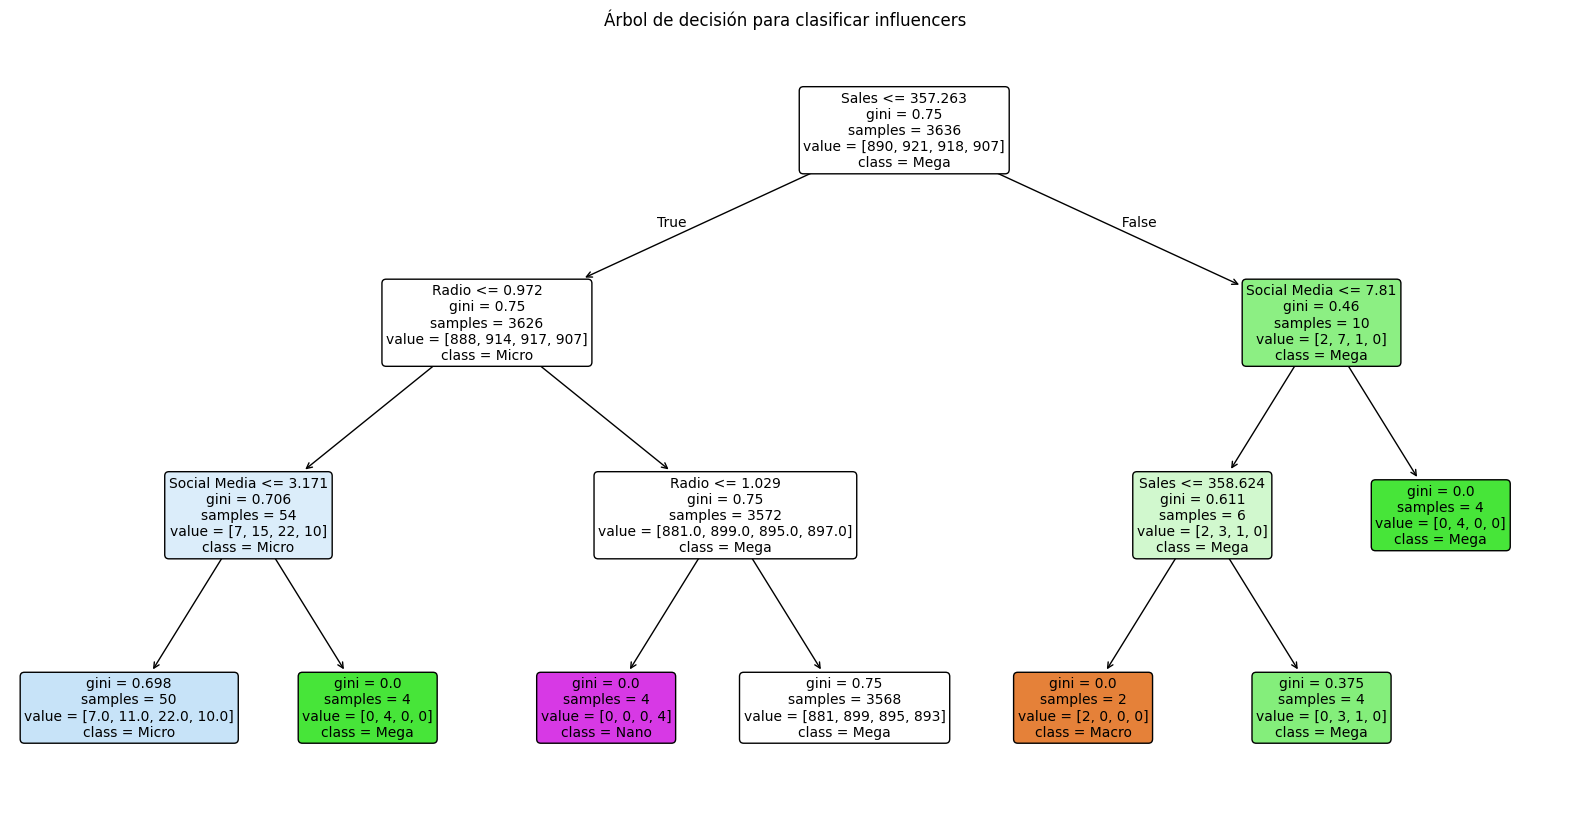

In [36]:
plt.figure(figsize=(20, 10))

plot_tree(
    model_cat,
    feature_names=x_cat.columns,
    class_names=model_cat.classes_,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title('Árbol de decisión para clasificar influencers')
plt.show()

In [37]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
y_pred_cat = model_cat.predict(X_test_cat)

print("Accuracy:", accuracy_score(y_test_cat, y_pred_cat))

print(classification_report(y_test_cat, y_pred_cat))

Accuracy: 0.25054945054945055
              precision    recall  f1-score   support

       Macro       0.50      0.00      0.01       222
        Mega       0.25      0.98      0.40       231
       Micro       0.10      0.00      0.01       230
        Nano       0.00      0.00      0.00       227

    accuracy                           0.25       910
   macro avg       0.21      0.25      0.10       910
weighted avg       0.21      0.25      0.11       910



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


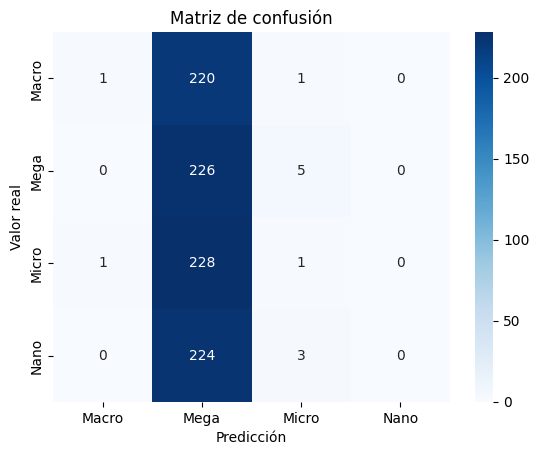

In [38]:
matriz = confusion_matrix(
    y_test_cat,
    y_pred_cat,
    labels=model_cat.classes_
)

sns.heatmap(
    matriz,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model_cat.classes_,
    yticklabels=model_cat.classes_
)

plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.title('Matriz de confusión')
plt.show()

<font color = "orange">
<div align="justify">
Como se puede observar no tiene sentido alguno, las variables no tienen la suficiente correlacion para poder determinar el tipo de influencer por lo que un gran porcentaje de sus predicciones caen en categoria 'Mega'.
</font>

In [39]:
#Con esto podemos observar el porcentaje real de cada tipo de influencer
df['Influencer'].value_counts(normalize=True) * 100

,proportion
Influencer,
Mega,25.328084
Micro,25.218723
Nano,24.912511
Macro,24.540682


<font color = "orange">
<div align="justify">
Con esto podemos verificar que 'Mega' no representa ni un 50% del total
</font>

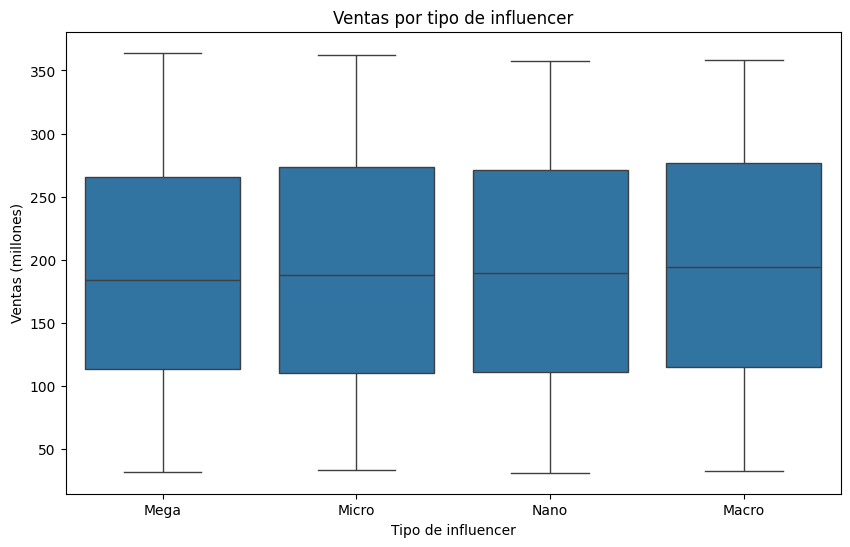

In [40]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=datos_cat, x='Influencer', y='Sales')

plt.title('Ventas por tipo de influencer')
plt.xlabel('Tipo de influencer')
plt.ylabel('Ventas (millones)')
plt.show()

Random Forest para predecir Sales/Ventas

In [41]:
from sklearn.ensemble import RandomForestRegressor
#RandomForestRegressor: crea muchos arboles de decision y promedia sus predicciones
rf = RandomForestRegressor(n_estimators=100, random_state=42)#n_estimators: numero de arboles del bosque
rf.fit(xtrain, y_train)#se entrena con los mismos datos que el arbol de decision
y_pred_rf = rf.predict(xtest)
print(f'MAE: {mean_absolute_error(y_test, y_pred_rf)}')
print(f'MSE: {mean_squared_error(y_test, y_pred_rf)}')
print(f'R2: {r2_score(y_test, y_pred_rf)}')

MAE: 2.720620301629014
MSE: 11.226261090709283
R2: 0.9986651939985541


<font color = "orange">
<div align="justify">
El Random Forest obtuvo un MAE de 2.72, un MSE de 11.24 y un R2 de 0.9987, mucho mejor que el árbol de decisión, que tuvo un MAE de 10.60, un MSE de 150.63 y un R2 de 0.9821. Esto quiere decir que en promedio sus predicciones se alejan solo 2.72 millones de las ventas reales. La mejora se debe a que, en lugar de usar un solo árbol de profundidad 3, el Random Forest combina 100 árboles entrenados con partes diferentes de los datos y promedia sus resultados, lo que le permite hacer predicciones más precisas.
</font>